<a href="https://colab.research.google.com/github/Adi21032004/Long-term-forecasting-using-transformer/blob/main/Patch_tst_implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
f = files.upload()

Saving cleaned_weather.csv to cleaned_weather (2).csv


In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import math

df = pd.read_csv('cleaned_weather.csv')

In [ ]:
df.head(5)
# df.plot(x='date',y='T', kind='bar',figsize=[16,8])
df['date'] = pd.to_datetime(df['date'])
df.dtypes
df.isna().sum()
df.describe()
df.shape


(52696, 21)

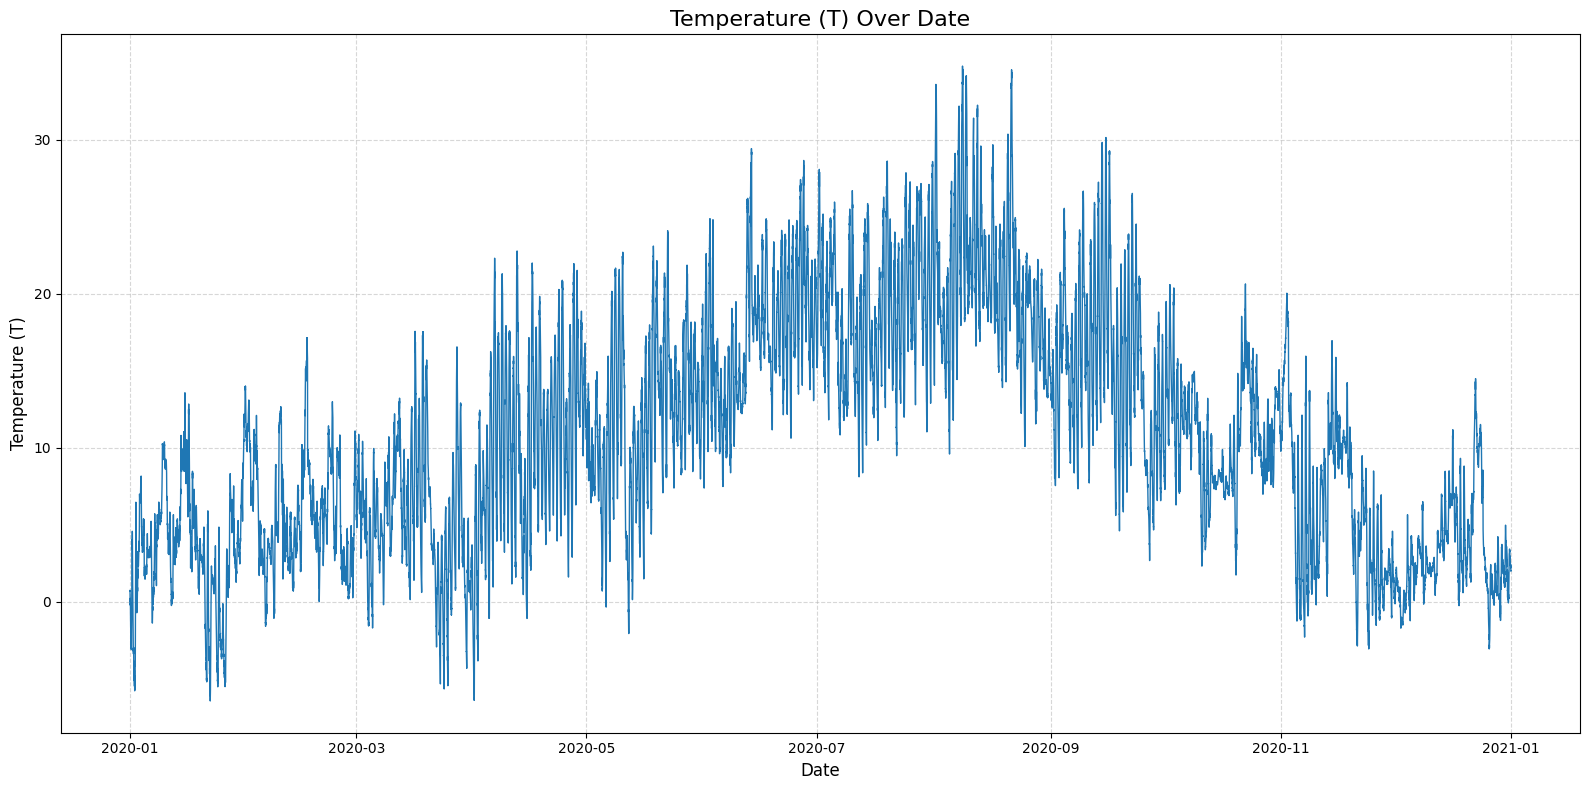

In [ ]:
import matplotlib.pyplot as plt

# Convert date column to datetime for proper alignment and sorting
df['date'] = pd.to_datetime(df['date'])

# Plot the relationship as a line chart
plt.figure(figsize=(16, 8))
plt.plot(df['date'], df['T'], color='tab:blue', linewidth=1)
plt.title('Temperature (T) Over Date', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Temperature (T)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
df = df.set_index('date')

In [ ]:
df.dtypes
ts = torch.tensor(df.values)
print(ts)
df

tensor([[1.0089e+03, 7.1000e-01, 2.7318e+02,  ..., 0.0000e+00, 0.0000e+00,
         1.1450e+01],
        [1.0088e+03, 7.5000e-01, 2.7322e+02,  ..., 0.0000e+00, 0.0000e+00,
         1.1510e+01],
        [1.0087e+03, 7.3000e-01, 2.7321e+02,  ..., 0.0000e+00, 0.0000e+00,
         1.1600e+01],
        ...,
        [9.7826e+02, 1.9900e+00, 2.7688e+02,  ..., 0.0000e+00, 0.0000e+00,
         1.3450e+01],
        [9.7826e+02, 2.0700e+00, 2.7695e+02,  ..., 0.0000e+00, 0.0000e+00,
         1.3470e+01],
        [9.7824e+02, 2.0100e+00, 2.7689e+02,  ..., 0.0000e+00, 0.0000e+00,
         1.3480e+01]], dtype=torch.float64)


,p,T,Tpot,Tdew,rh,VPmax,VPact,VPdef,sh,H2OC,rho,wv,max. wv,wd,rain,raining,SWDR,PAR,max. PAR,Tlog
date,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:10:00,1008.89,0.71,273.18,-1.33,86.1,6.43,5.54,0.89,3.42,5.49,1280.62,1.02,1.60,224.3,0.0,0.0,0.0,0.0,0.0,11.45
2020-01-01 00:20:00,1008.76,0.75,273.22,-1.44,85.2,6.45,5.49,0.95,3.39,5.45,1280.33,0.43,0.84,206.8,0.0,0.0,0.0,0.0,0.0,11.51
2020-01-01 00:30:00,1008.66,0.73,273.21,-1.48,85.1,6.44,5.48,0.96,3.39,5.43,1280.29,0.61,1.48,197.1,0.0,0.0,0.0,0.0,0.0,11.60
2020-01-01 00:40:00,1008.64,0.37,272.86,-1.64,86.3,6.27,5.41,0.86,3.35,5.37,1281.97,1.11,1.48,206.4,0.0,0.0,0.0,0.0,0.0,11.70
2020-01-01 00:50:00,1008.61,0.33,272.82,-1.50,87.4,6.26,5.47,0.79,3.38,5.42,1282.08,0.49,1.40,209.6,0.0,0.0,0.0,0.0,0.0,11.81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-31 23:20:00,978.32,2.28,277.16,-0.80,80.0,7.20,5.76,1.44,3.67,5.89,1234.61,0.73,1.40,180.6,0.0,0.0,0.0,0.0,0.0,13.40
2020-12-31 23:30:00,978.30,2.13,277.01,-0.43,83.1,7.12,5.92,1.20,3.77,6.05,1235.20,0.43,0.82,174.0,0.0,0.0,0.0,0.0,0.0,13.42
2020-12-31 23:40:00,978.26,1.99,276.88,-0.71,82.2,7.05,5.80,1.26,3.69,5.93,1235.82,0.38,0.76,248.9,0.0,0.0,0.0,0.0,0.0,13.45


**Instance Norm and Patching**

In [ ]:
class CreatePatch(nn.Module):
    def __init__(self,seq_len: int, patch_len: int, stride: int):
      super().__init__()
      self.seq_len = seq_len
      self.patch_len = patch_len
      self.stride = stride

    def forward(self,x):
      rows = x.shape[0]
      batches = int(rows/self.seq_len)

      x = x.contiguous().view(batches,self.seq_len,x.shape[-1])  #(batch,seqlen,features)
      x = x.transpose(-1,-2) #(batch,features,seqlen)

      # N = int(self.seq_len/self.patch_len)
      # x = x.contiguous().view(x.shape[0],x.shape[1],self.patch_len,N) #(batch,features,patchlen,patches) , no overlap up to this point

      # stride!=patch_len
      x = nn.functional.pad(x,(0,self.stride),mode='replicate') #added a pad of stride length at the end
      x = x.unfold(-1,size=self.patch_len, step=self.stride) #(batch,features,patches,patchlen),(B,F,N,P)

      return x



In [ ]:
create_patch = CreatePatch(336,16,8)
# here ts.shape[0] might not be divisible by seqlen
# we make sure that it is divisible to correctly use torch.view() function
seq_len = 336  #this is the lookup window
correct_len = (ts.shape[0]//seq_len) * seq_len  #// floor division, round down

truncated_ts = ts[ : correct_len]
x = create_patch(truncated_ts)
x.shape
# x.dtype
# remain_ts = ts[correct_len: ]
# remain_ts.shape
# truncated_ts.shape

torch.Size([156, 20, 42, 16])

**Projection and Position Embedding**

In [ ]:
class Project_and_PositionalEmbedding(nn.Module):
  def __init__(self,d_model: int, patches: int, patch_len: int, dropout: float):
    super().__init__()
    self.D = d_model
    self.N = patches
    self.dropout = nn.Dropout(dropout)
    self.proj = nn.Linear(patch_len, d_model) #internally it does out = inp * w.Transpose + bias
    # weight is internally stored as (D,P) opposite to what we provided, then do wT

    pe = torch.zeros(patches,d_model) #(N,D)
    position = torch.arange(0,patches, dtype=torch.float).unsqueeze(1)
    div_term = torch.exp(torch.arange(0,d_model,2).float() * (-math.log(10000.0)/d_model))

    # pe is (N,D)

    pe[:, 0::2] = torch.sin(position*div_term) # (N,D/2)
    pe[:, 1::2] = torch.cos(position*div_term)

    self.register_buffer('pe',pe.unsqueeze(0).unsqueeze(0))

  def forward(self,x):
    # x = (B,F,N,P) -> (B,F,N,D)
    x = self.proj(x) + self.pe[:x.shape[-2] ,:].requires_grad_(False) #pe for all the patches in the input, but why not just self.pe

    #there might be a mistake in the projection, not able to catch right now, mathematically looks alright
    #problem solve , output x is (batch,features,patches,d_model),(B,F,N,D)

    return self.dropout(x)


In [ ]:
D = 128
N = x.shape[-2]
P = x.shape[-1]
dropout = 0.2
PP = Project_and_PositionalEmbedding(D,N,P,dropout)
PP.double() #all the parameter to float64 like the input dtype
xx = PP(x)
xx.shape # (B,F,N,D)

torch.Size([156, 20, 42, 128])

**Transformer backbone**

In [ ]:
class LayerNormalisation(nn.Module):
  def __init__(self,feature: int, eps: float=10**-6):
    super().__init__()
    self.eps = eps
    self.alpha = nn.Parameter(torch.ones(feature))
    self.bias = nn.Parameter(torch.zeros(feature))
    # feature=D

  def forward(self,x):
    mean = x.mean(dim=-1 , keepdim=True)
    std = x.std(dim=-1, keepdim=True)

    return self.alpha *(x-mean)/(std + self.eps) + self.bias

In [ ]:
class FeedForward(nn.Module):
  def __init__(self,d_model: int, dff: int, dropout: float):
    super().__init__()
    self.dropout = nn.Dropout(dropout)
    self.linear1 = nn.Linear(d_model,dff)
    self.linear2 = nn.Linear(dff,d_model)
    self.gelu = nn.GELU()

  def forward(self,x):
    return self.linear2(self.dropout(self.gelu(self.linear1(x))))

In [ ]:
class ResidualConnection(nn.Module):
  def __init__(self,feature: int, dropout: float):
    super().__init__()
    self.dropout = nn.Dropout(dropout)
    self.layer_norm = LayerNormalisation(feature)

  def forward(self,x,sublayer):
    return x + self.dropout((sublayer(self.layer_norm(x))))

In [ ]:
class MultiHeadAttention(nn.Module):
  def __init__(self,h: int, d_model: int,dropout: float):
    super().__init__()
    self.h = h
    self.d_model = d_model
    assert d_model%h == 0, 'd_model is not divisible by h'
    self.d_k = d_model//h

    self.w_q = nn.Linear(d_model,d_model) #(D,D)
    self.w_k = nn.Linear(d_model,d_model) #(D,D)
    self.w_v = nn.Linear(d_model,self.h*d_model) #(D,h*D)

    self.w_o = nn.Linear(self.h*d_model,d_model)
    self.dropout = nn.Dropout(dropout,inplace=False)

  @staticmethod
  def attention(query,key,value,mask,dropout: nn.Dropout):
    d_k = query.shape[-1]
    attention_score = (query @ key.transpose(-1,-2))/math.sqrt(d_k)

    if mask is not None:
      attention_score.masked_fill_(mask==0, -1e9)

    attention_score = attention_score.softmax(dim=-1)

    if dropout is not None:
      attention_score = dropout(attention_score)

    return (attention_score @ value), attention_score

  def forward(self,q,k,v,mask):
    query = self.w_q(q) #(N,D)
    key = self.w_k(k)  #(N,D)
    value = self.w_v(v)  #(N,h*D)

    query = query.view(query.shape[0],query.shape[1],query.shape[2],self.h,self.d_k).transpose(2,3) #(B,F,h,N,dk)
    key = key.view(key.shape[0],key.shape[1],key.shape[2],self.h,self.d_k).transpose(2,3) #(B,F,h,N,dk)
    value = value.view(value.shape[0],value.shape[1],value.shape[2],self.h,self.d_model).transpose(2,3) #(B,F,h,N,D) as per the paper

    x, self.AttentionScore = MultiHeadAttention.attention(query,key,value,mask,self.dropout)
    # x = (B,F,h,N,D)

    x = x.transpose(2,3).contiguous().view(x.shape[0], x.shape[1],-1, self.h * self.d_model)
    # x=(B,F,h,N,D) -> (B,F,N,h,D) -> (B,F,N,h*D)
    # w0 = (h*D,D)
    # x*w0 = Head = (B,F,N,D)

    return self.w_o(x)

In [ ]:
class Encoder(nn.Module):
  def __init__(self,multi_head_attention: MultiHeadAttention,feed_forward: FeedForward, features: int, dropout: float):
    super().__init__()
    self.MH_attention = multi_head_attention
    self.FFN = feed_forward
    self.residual_connections = nn.ModuleList([ResidualConnection(features, dropout) for _ in range(2)])

  def forward(self,x,src_mask):
    x = self.residual_connections[0](x, lambda x: self.MH_attention(x,x,x,src_mask))
    x = self.residual_connections[1](x, self.FFN)
    return x


In [ ]:
class EncoderLayers(nn.Module):
  def __init__(self,layers: nn.ModuleList, features: int) -> None:
    super().__init__()
    self.layers = layers
    self.norm = LayerNormalisation(features)

  def forward(self,x,src_mask):
    for layer in self.layers:
      x = layer(x,src_mask)

    return self.norm(x)

In [ ]:
class Flatten_and_LinearHead(nn.Module):
  def __init__(self,patches: int, d_model: int, target_window: int):
    super().__init__()
    self.flatten = nn.Flatten(-2,-1)
    self.linear = nn.Linear(patches*d_model, target_window)

  def forward(self,x):
    x = self.flatten(x)
    x = self.linear(x)
    return x

In [ ]:
class Transformer(nn.Module):
  def __init__(self,proj_pe: Project_and_PositionalEmbedding, encoder: EncoderLayers, flatten: Flatten_and_LinearHead):
    super().__init__()
    self.pp = proj_pe
    self.encoder = encoder
    self.flatten = flatten

  def encode(self,x,src_mask):
    x = self.pp(x)
    return self.encoder(x,src_mask)

  def Flatten_head(self,x):
    return self.flatten(x)


In [ ]:
def Build_Transformer(seq_len: int, patches:int, patch_len: int, stride: int, d_model: int,
                      feature: int, target_window: int, dropout: float):

  proj_pe = Project_and_PositionalEmbedding(d_model,patches,patch_len,dropout)
  # proj_pe.double()

  encoder_block = []
  for _ in range(3):
    MHA = MultiHeadAttention(8,d_model,dropout)
    FFN = FeedForward(d_model,d_model*4,dropout)
    encoder = Encoder(MHA,FFN,feature,dropout)
    encoder_block.append(encoder)

  encoder = EncoderLayers(nn.ModuleList(encoder_block),feature)
  flatten = Flatten_and_LinearHead(patches, d_model, target_window)
  transformer = Transformer(proj_pe,encoder,flatten)

  for p in transformer.parameters():
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)

  return transformer

In [ ]:
seq_len=336
patch_len=16
stride=8
d_model=128
feature=d_model
dropout=0.2
target = 92
patches = x.shape[-2]

# Convert truncated_ts to float (float32) to match standard PyTorch model parameter types

transformer = Build_Transformer(seq_len, patches, patch_len, stride, d_model, feature, target, dropout)
out = transformer.encode(x.float(),None)
out = transformer.Flatten_head(out)

In [ ]:
out.shape

torch.Size([156, 20, 92])

**Training and Loss function**